# 01 · Preprocessing — Steen 2021 DLBCL (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, and **resolve the manifold's compartments before any gate call**. Steen et al.
(2021) profiled diffuse large B-cell lymphoma biopsies by 10x; the malignant compartment here spans
three well-populated tumours. Critically, the malignant manifold carries a **distinct proliferative
lobe** (≈95% cycling) alongside a low-cycling body — so, following the Kürten/Lin lobe-identity
lesson, we identify each sub-region's biology (signatures + cell cycle) here and **scope the
trajectory (in 02) to the low-cycling lobe that reproduces the reference embryonic relationships**,
where Gastrulation is not proliferation-confounded. Every tunable choice is derived from this
dataset, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Steen2021_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Steen2021_Hematologic | category: Hematologic


### Load malignant compartment
Steen et al. supply a per-cell `cell_type` in which **Malignant** is an explicit label (their inferCNV/genetics-backed call); the loader exposes it as `celltype`, taken directly. 10x UMI counts are `normalize_total`- then `log1p`-transformed by the loader.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| celltypes:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant raw:', adata.shape[0], '| samples:', adata.obs['sample'].nunique())
print('X max %.2f (log1p of normalize_total UMI)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Steen2021_Hematologic
Done.
full atlas: (18197, 31241) | celltypes: {'T_cell': 12142, 'Malignant': 2522, 'B_cell': 2013, 'Macrophage': 550, 'NK_cell': 213, 'Plasma': 85}
malignant raw: 2522 | samples: 4
X max 7.59 (log1p of normalize_total UMI)


### Sample thresholding — multiplicative gap-finding, floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the separatrix
between tumour-bearing samples and spillover). Here the counts are 1546 / 561 / 371 / 44; the
dominant cliff is 371→44 (ratio 8.4, and 3.1× the runner-up), a clean spillover cliff whose upper
side (44) sits far below 2×the 100-cell floor — so the geometric-mean threshold (127) drops the
thin 44-cell sample and keeps the three well-populated tumours.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; FLOOR = 100
dominant = (srt[0]/srt[1] >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {srt[0]:.2f}); top/second = {srt[0]/srt[1]:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print('threshold =', thresh, '(geometric mean of the dominant cliff)' if dominant else '(floor)')
keep = n.index[n >= thresh]; adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample {int(n[n>=thresh].min())}) -> after threshold {adata.shape[0]} cells')

sorted per-sample counts: {'DLBCL002B': np.int64(1546), 'DLBCL007B': np.int64(561), 'DLBCL008B': np.int64(371), 'DLBCL111B': np.int64(44)}
gap ratios: ['1546->561:2.76', '561->371:1.51', '371->44:8.43']
argmax gap 371->44 (ratio 8.43); top/second = 3.06; dominant cliff = True
threshold = 127 (geometric mean of the dominant cliff)
kept 3/4 samples (min per-sample 371) -> after threshold 2478 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by a same-sample-neighbour-fraction sweep (lower = better mixing): DLBCL malignant
cells are strongly patient-specific (distinct clonal/CNV states), pre-Harmony mixing is nil. Mixing
improves sharply from theta=2 to theta=5 and then flattens (theta=10 within noise of theta=5), so
the mixing floor is reached; we take the strongest integration on the plateau (theta=10) to suppress
the patient batch without collapsing structure. PC count (20) and UMAP spread (1.3) follow the
comparable-scale 10x precedents.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _ssf(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _ssf(adata.obsm['X_pca'][:,:20]); sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _ssf(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing floor reached by theta=5; strongest integration for the strong DLBCL patient effect)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1153 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1153
same-sample neighbour fraction | pre 1.000 | sweep {2: 0.947, 5: 0.737, 10: 0.745}
selected theta = 10 (mixing floor reached by theta=5; strongest integration for the strong DLBCL patient effect)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside the main connected component. Here the manifold is already a single connected component — no islands.

In [ ]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0])

removed 0 cells in 0 detached islands
after island removal: 2478


### Compartment split + cell-cycle identity — the scope decision (data-driven)
Low-resolution Leiden (res=0.15) resolves the manifold's lobes. Unlike Olalekan's single low-cycling
body, this DLBCL manifold splits into **two** lobes: a large low-cycling body and a small, almost
entirely cycling lobe (proliferative compartment). We quantify cycling and a proliferation score per
lobe, then flag the **low-cycling lobe as the developmental compartment** to carry the trajectory in
02. This is the Kürten/Lin fork: on the whole manifold Gastrulation is confounded by proliferation,
so the trajectory must be scoped to the lobe where the embryonic relationships are not cycle-driven
(verified in 02).

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
cyc_by = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('cycling fraction per lobe:', cyc_by.round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
# developmental lobe = the LARGEST LOW-CYCLING lobe (cycling fraction < 0.5)
lowcyc = cyc_by[cyc_by < 0.5]
dev_lobe = adata.obs['lobe'].value_counts()[lowcyc.index].idxmax()
adata.obs['compartment'] = np.where(adata.obs['lobe']==dev_lobe, 'Developmental', 'Proliferative')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
adata.uns['dev_lobe'] = str(dev_lobe)
print('developmental (low-cycling) lobe =', dev_lobe, '| compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 1965, '1': 513}
overall cycling fraction: 0.347
cycling fraction per lobe: {'0': 0.189, '1': 0.955}
proliferation score per lobe: {'0': -0.261, '1': 0.422}
developmental (low-cycling) lobe = 0 | compartments: {'Developmental': 1965, 'Proliferative': 513}


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so panels are shown after a single
**rigid rotation** to horizontal (distance-preserving, *not* a re-embedding). Angle = the manifold's
axis of maximal variance; the sign places the **gastrulation/somitogenesis-high, neural-crest-low**
developmental origin on the **left** so pseudotime runs left→right once fit in 02. Modules are scored
here against the shared union pool solely to orient the layout.

In [ ]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0]); A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]]); xyr = c @ Rm.T
w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect {aspect:.2f} | rigid rotation {np.degrees(th):+.1f}deg, Gast/pSom origin on left (X_umap_lin)')

manifold aspect 1.65 | rigid rotation +12.5deg, Gast/pSom origin on left (X_umap_lin)


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar alone.

iLISI median: pre 1.00 -> post-Harmony(theta=10) 1.88 of 3 samples (1=segregated, 3=perfect mix)
3 samples share one connected component (0 islands removed); embedding shows one continuous cloud, no per-patient archipelago.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


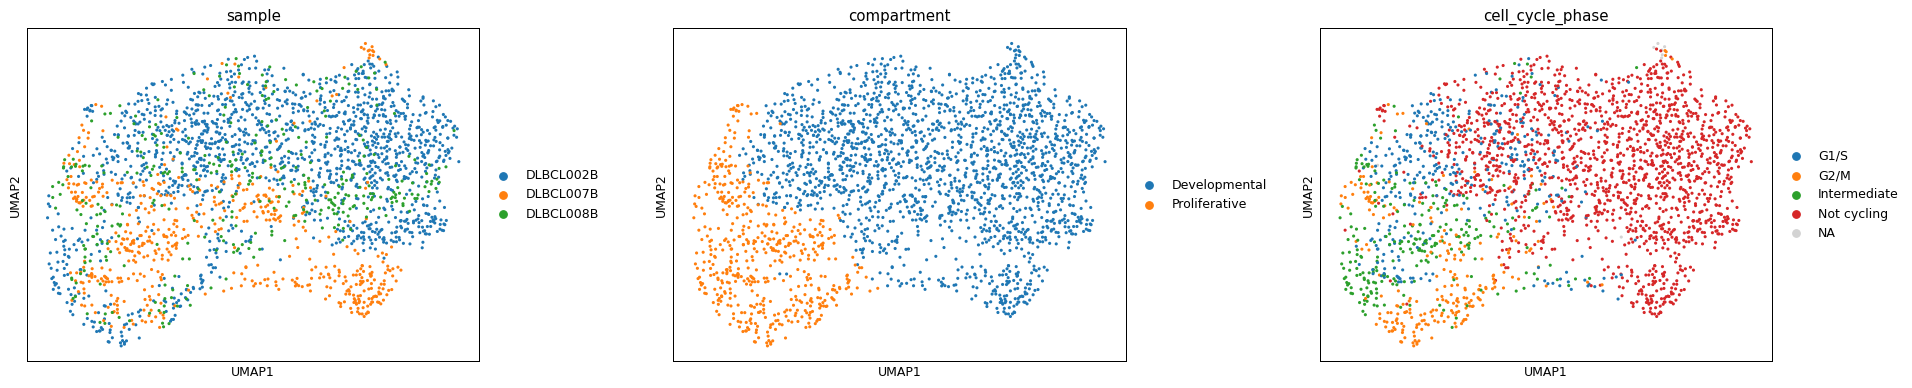

In [ ]:
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
ns = adata.obs['sample'].nunique()
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {ns} samples (1=segregated, {ns}=perfect mix)')
print(f'{ns} samples share one connected component (0 islands removed); embedding shows one continuous cloud, no per-patient archipelago.')
sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'], size=25, wspace=.3)
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

### Save processed data
Coerce mixed-type object metadata to numeric/string so the manifold is h5ad-serializable; analysis-relevant columns preserved.

In [ ]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','disease','disease_subtype','patient','cycling'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2478, 18178)


### Sample-integration figure (deliverable)
House style `figsize=(3.5,1.5)`, `size=30`, on the house orientation (`X_umap_lin`). Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence over the whole malignant manifold.

saved samples.pdf | cells: 2478


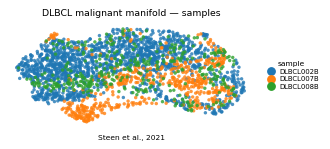

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('DLBCL malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Steen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])